In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [40]:
from google.colab import drive
drive.mount('/content/drive')

CAMINHO_TESTES = Path("/content/drive/MyDrive/PESQUISA/01_EXPERIMENTOS/2_pipeline_v1_pre_pros/testes_pre_pros")
caminhos_imagens = sorted(list(CAMINHO_TESTES.glob("*.jpg")) + list(CAMINHO_TESTES.glob("*.png")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


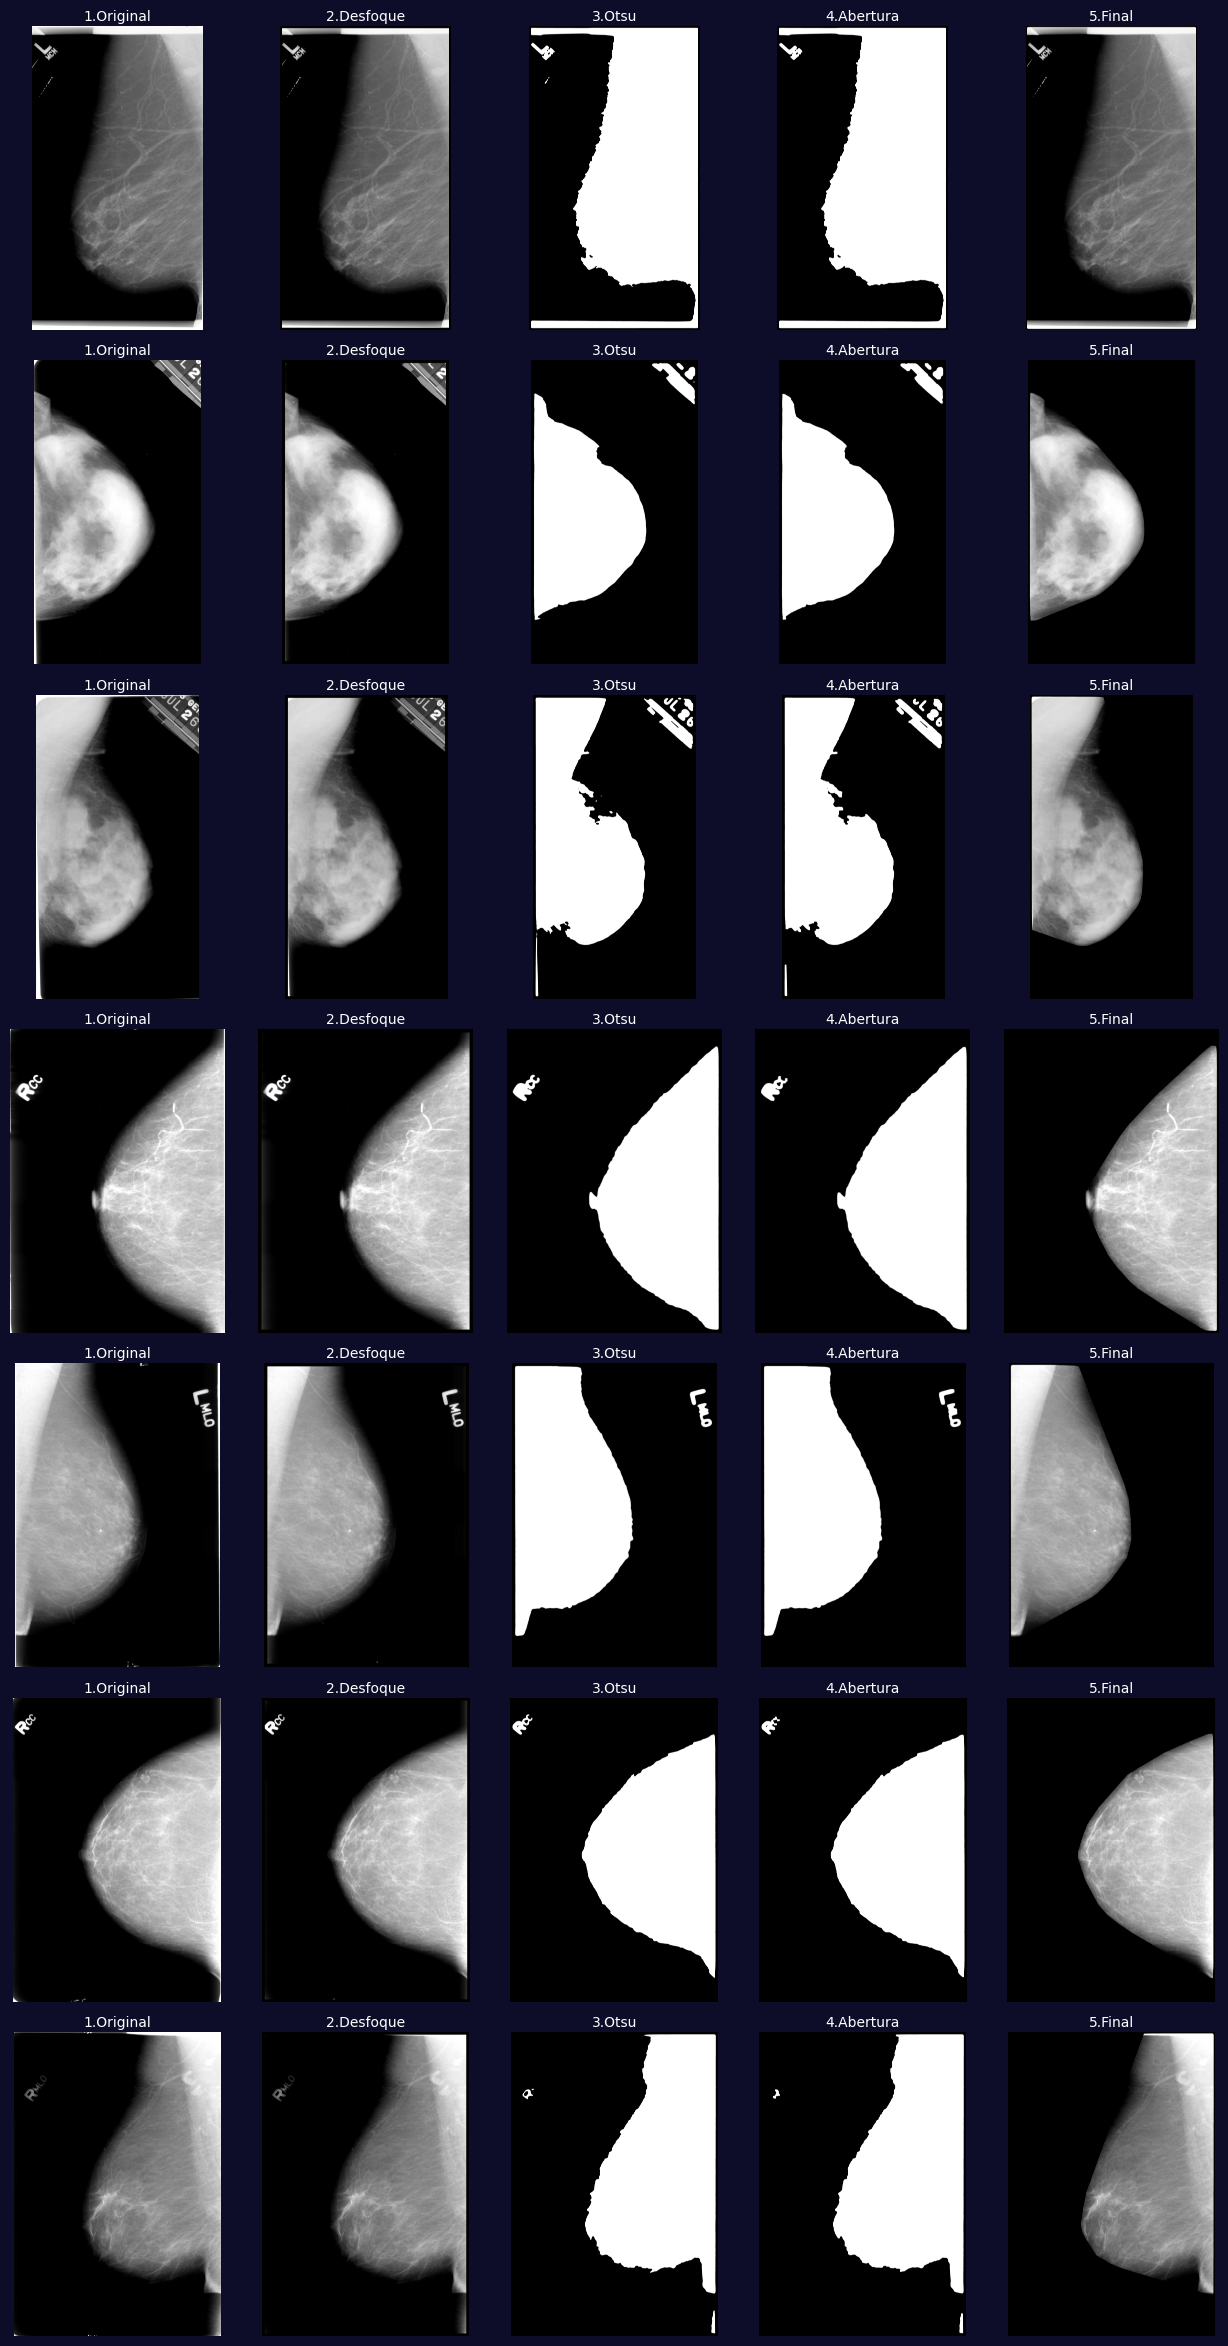

In [41]:
fig, axes = plt.subplots(nrows=7, ncols=5, figsize=(16, 30))
cor_fundo = '#0d0d29'
fig.patch.set_facecolor(cor_fundo)

for i, caminho in enumerate(caminhos_imagens):
    img_original = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)

    # Borda em preto para remover a moldura branca das bordas
    margem = 50
    img_cortada = img_original.copy()
    img_cortada[:margem, :] = 0
    img_cortada[-margem:, :] = 0
    img_cortada[:, :margem] = 0
    img_cortada[:, -margem:] = 0

    # Desfoque
    img_blur = cv2.GaussianBlur(img_cortada, (81, 81), 0)

    # Binarização de Otsu
    _, img_binaria = cv2.threshold(img_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Abertura morfológica
    kernel_abertura = np.ones((31, 31), np.uint8)
    img_abertura = cv2.morphologyEx(img_binaria, cv2.MORPH_OPEN, kernel_abertura)

    # Encontra a mama pelo maior contorno, suaviza e aplica a margem
    contornos, _ = cv2.findContours(img_abertura, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contornos:
        maior_contorno = max(contornos, key=cv2.contourArea)
        hull = cv2.convexHull(maior_contorno)

        # Cria a máscara e dilata para margem de segurança
        mascara = np.zeros_like(img_original)
        cv2.drawContours(mascara, [hull], -1, 255, thickness=cv2.FILLED)
        kernel_dilatacao = np.ones((35, 35), np.uint8)
        mascara_dilatada = cv2.dilate(mascara, kernel_dilatacao, iterations=1)

        # Aplica máscara na imagem original
        img_final = cv2.bitwise_and(img_original, img_original, mask=mascara_dilatada)
    else:
        img_final = img_original

    etapas = [img_original, img_cortada, img_binaria, img_abertura, img_final]
    titulos = ["1.Original", "2.Desfoque", "3.Otsu", "4.Abertura", "5.Final"]

    for j in range(5):
        axes[i, j].imshow(etapas[j], cmap='gray')
        axes[i, j].axis('off')
        axes[i, j].set_facecolor(cor_fundo)
        axes[i, j].set_title(titulos[j], fontsize=10, color='white', pad=4)

        if j == 0:
            nome_arquivo = caminho.name[:20] + "..." if len(caminho.name) > 20 else caminho.name
            axes[i, j].set_ylabel(nome_arquivo, fontsize=10, color='white')

plt.subplots_adjust(wspace=0.01, hspace=0.1)
plt.show()